<a href="https://colab.research.google.com/github/AshleyH2026/A04-clustering/blob/main/A04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ashley Hughes

**Date:** 10/13/2026

Question 1: 

Scatterplots 



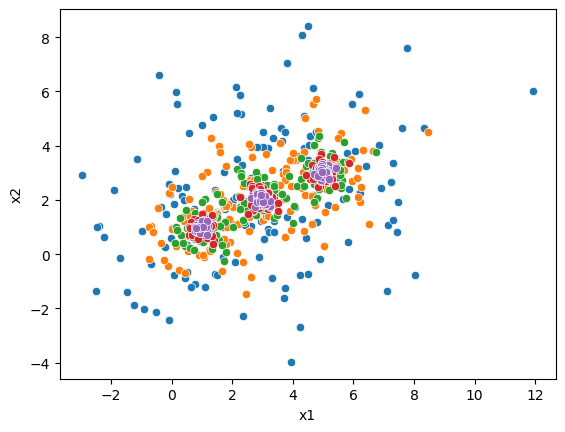




Scree plots 



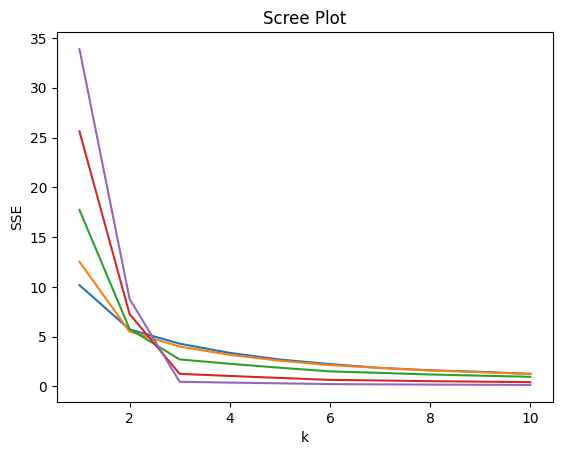


For the scatterplots, as noise goes up, the data becomes more and more spread out - making it less hard to see groups in the data. 
As the noise goes down, however, we can see more distinct groups and trends.

For the scree plots, as noise decreases, the where the SSE drops the most becomes more distinct.
As noise increases, this first drop in SSE becomes less and less dramatic.
In other words, the "elbow" becomes more pronounced, making it easier to choose a k value.

The idea behind the "elbow" show the least amount of clusters that provide you the lowest SSE,
or the most dramatic decrease in SSE. You don't want to choose too many clusters because you don't
want to overfit the data and give too much influence to noise. So, we use the elbow to find the 
best point where there are just enough clusters to lower the SSE while also not overfitting the data.



In [53]:
# Your Phase 1 solution to the problem goes here.
# Question 1:
print("Question 1: \n")

# Import
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Pasted provided code

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# Scatterplots
plt.figure()
ax = sns.scatterplot(data=df2_0, x="x1", y="x2")
ax = sns.scatterplot(data=df1_0, x="x1", y="x2")
ax = sns.scatterplot(data=df0_5, x="x1", y="x2")
ax = sns.scatterplot(data=df0_25, x="x1", y="x2")
ax = sns.scatterplot(data=df0_125, x="x1", y="x2")
print("Scatterplots \n")
plt.show()

print("\n\n")

# Scree plots
plt.figure()
features = ["x1", "x2"]
unscaled = df2_0.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

features = ["x1", "x2"]
unscaled = df1_0.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

features = ["x1", "x2"]
unscaled = df0_5.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

features = ["x1", "x2"]
unscaled = df0_25.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

features = ["x1", "x2"]
unscaled = df0_125.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
print("Scree plots \n")
plt.show()


# Explanation
print("""
For the scatterplots, as noise goes up, the data becomes more and more spread out - making it less hard to see groups in the data.
As the noise goes down, however, we can see more distinct groups and trends.

For the scree plots, as noise decreases, the where the SSE drops the most becomes more distinct.
As noise increases, this first drop in SSE becomes less and less dramatic.
In other words, the "elbow" becomes more pronounced, making it easier to choose a k value.

The idea behind the "elbow" show the least amount of clusters that provide you the lowest SSE,
or the most dramatic decrease in SSE. You don't want to choose too many clusters because you don't
want to overfit the data and give too much influence to noise. So, we use the elbow to find the
best point where there are just enough clusters to lower the SSE while also not overfitting the data.
""")

Question 2: 

Pt1 - cleaning data
Number of rows after cleaning: 148

No further cleaning of variables appear to be needed. No null values and can't see odd characters or spaces in data.
Pt2 - Spending (2020 USD) and Spending per capita
Scree plot 



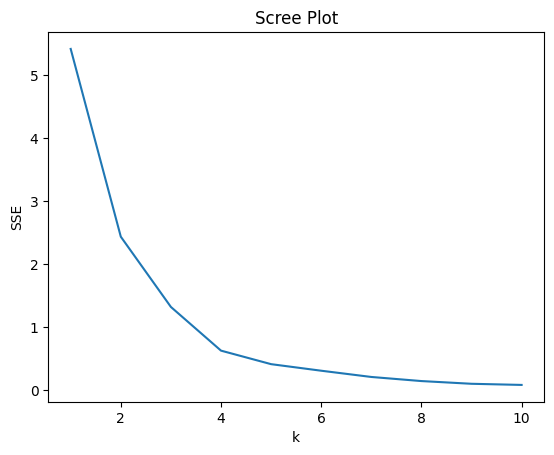




Scatter plot 



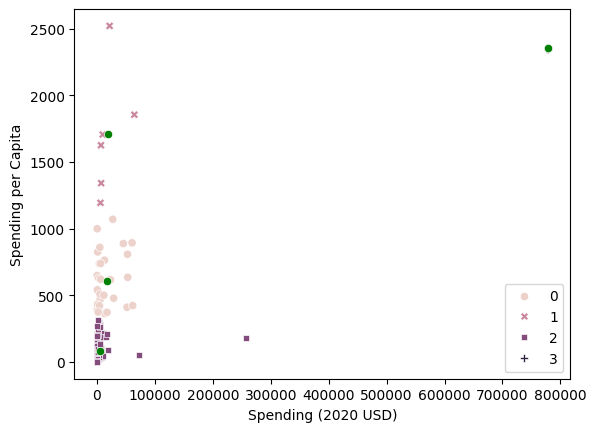




Describe table for Spending (2020 USD) and Spending per capita
        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353 

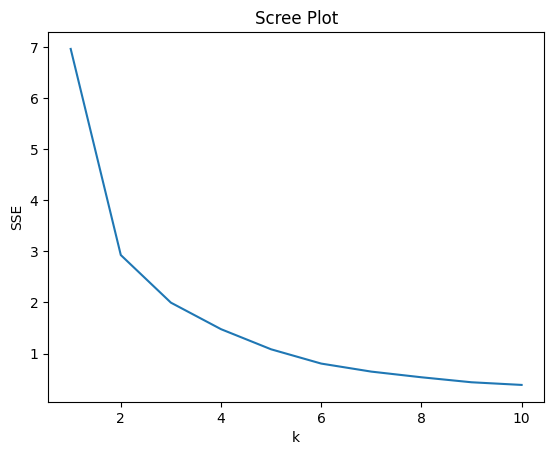




Scatter plot 



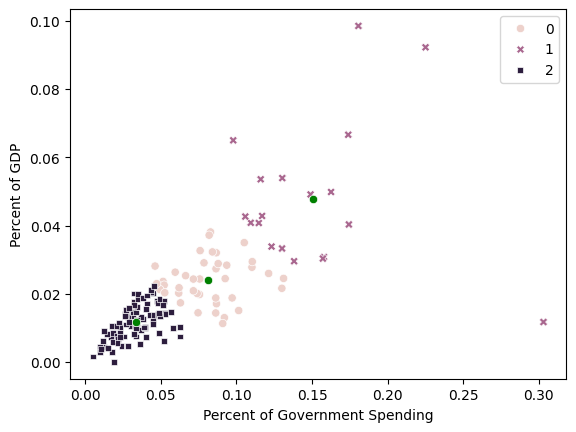




Describe table for Percent of Government Spending and Percent of GDP
        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 40.0  0.081391  0.021601  0.046211   
1                                 19.0  0.150875  0.048785  0.097882   
2                                 89.0  0.033497  0.013242  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.065564  0.082430  0.092176  0.131184           40.0  0.023924   
1        0.116521  0.138143  0.168248  0.303027           19.0  0.047657   
2        0.023300  0.033620  0.043645  0.062685           89.0  0.011698   

                                      

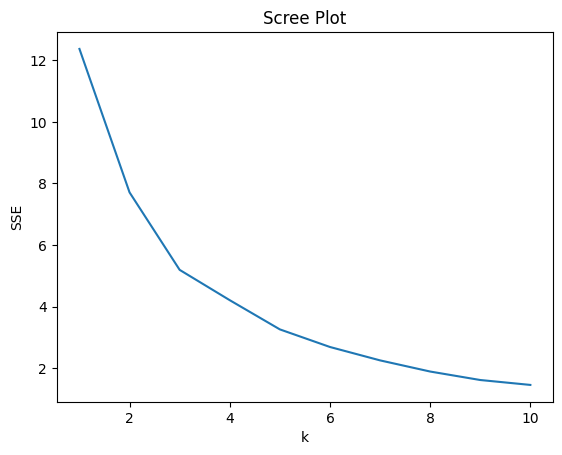




Describe table for all four variables
        Spending (2020 USD)                                           \
                      count          mean            std         min   
cluster                                                                
0                      40.0  25561.803543  122832.149821   23.306688   
1                      19.0  10519.956662   19274.722071  298.382192   
2                      89.0   8139.363336   29425.494754    8.622460   

                                                              \
                25%          50%          75%            max   
cluster                                                        
0        282.062109  1042.564882  5718.080448  778397.200000   
1        670.689216  2237.764706  8324.659893   64558.400000   
2         89.409368   483.415023  3732.673666  257973.429834   

        Spending per Capita              ... Percent of Government Spending  \
                      count        mean  ...                  

In [54]:
# Your Phase 1 solution to the problem goes here.
# Question 2:
print("Question 2: \n")

# Import
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

df = pd.read_csv('SIPRI Military Expenditure Database.csv')

# Q1 - Clean military spending data
# Filter the rows to select only the year 2020, and drop all rows with missing values.
df_2020 = df[df['Year'] == 2020]
df_clean = df_2020.dropna().copy()
print("Pt1 - cleaning data")
print("Number of rows after cleaning: " + str(len(df_clean['Country'])) + "\n")

# Further cleaning of variables?
print("No further cleaning of variables appear to be needed. No null values and can't see odd characters or spaces in data.")

# Q2
print("Pt2 - Spending (2020 USD) and Spending per capita")
# Max-min normalize Spending (2020 USD) and Spending per Capita
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df_clean.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

# Scree plot - determining optimal number of clusters for kmeans clustering algorithm
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
plt.figure()
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
print("Scree plot \n")
plt.show()

print("\n\n")

# Scatter plot of Spending (2020 USD) and Spending per capita; hue dots by cluster
plt.figure()
model = KMeans(n_clusters=4, n_init="auto", random_state=0).fit(X)
df_clean["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
ax = sns.scatterplot(
    data=df_clean, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax)
print("Scatter plot \n")
plt.show()

print("\n\n")

# Describe table conditional on cluster
table = df_clean.groupby("cluster")[features].describe()
print("Describe table for Spending (2020 USD) and Spending per capita")
print(table)

# What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
print("""
Based on both the scatter plot and the describe table, there are 4 different clusters. The first three all have relatively low spending in USD,
though they differ in their spending per capita, with groups zero and three having larger and larger spending per capita.
The fourth cluster consists of one very extreme outlier, which appears to be the United States. It demonstrates significantly
larger spending in USD as well as a comparatively high spending per capita.
""")

print("\n\n")


# Q3
print("Pt3 - Percent of Government Spending and Percent of GDP")
# Repeat part 2 for Percent of Government Spending and Percent of GDP.
# Max-min normalize Percent of Government Spending and Percent of GDP
features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = df_clean.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

# Scree plot - determining optimal number of clusters for kmeans clustering algorithm
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
plt.figure()
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
print("Scree plot \n")
plt.show()

print("\n\n")

# Scatter plot of Percent of Government Spending and Percent of GDP; hue dots by cluster
plt.figure()
model = KMeans(n_clusters=3, n_init="auto", random_state=0).fit(X)
df_clean["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
ax = sns.scatterplot(
    data=df_clean, x="Percent of Government Spending", y="Percent of GDP", hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax)
print("Scatter plot \n")
plt.show()

print("\n\n")

# Describe table conditional on cluster
table = df_clean.groupby("cluster")[features].describe()
print("Describe table for Percent of Government Spending and Percent of GDP")
print(table)

#How do your results compare to part 2?

print("""
Based on the scree plot and the elbow, I only chose 3 clusters.

Looking at both the scatter plot and the describe table, the groups are a bit similar in their magnitude.
Group 2 values typically have a lower percent of government spending and percent of gdp, and group
0 has higher values - serving as a sort of middle ground. Finally group 1 has a lot of the higher
value percentages and has more variable data (less closely clustered), containing more of the outliers in the data
(as seen by its comparably high standard deviation).
Group 1 has some points with just unusually high percent of governemnt spending (and still relatively
high percent of gdp - just not too extreme), and vice versa.
""")

print("\n\n")

# Q4
print("Pt4 - all four variables")
# Use  k  means clustering with all four numeric variables: Spending (2020 USD), Spending per Capita, Percent of Government Spending, and Percent of GDP. How do your results compare to the previous two parts?
# Max-min normalize all four numeric variables
features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = df_clean.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

# Scree plot - determining optimal number of clusters for kmeans clustering algorithm
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
plt.figure()
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
print("Scree plot \n")
plt.show()

print("\n\n")

# Describe table conditional on cluster
table = df_clean.groupby("cluster")[features].describe()
print("Describe table for all four variables")
print(table)

# How do your results compare to the previous two parts?
print("""
Combining all four variables makes the scree plot "elbow" even more undefined and unclear.
Unlike the other two parts, group 0 actually has the largest standard deviation and mean,
though group 2 still has the lowest mean.
""")
print("\n\n")

# Q5
# Did the k -MC algorithm find any useful patterns for you in analyzing the spending?
print("""
The k-MC algorithm helped us view more patterns while analyzing the spending by dividing
the data into smaller parts so we can do describe statistics on them individually.
For instance, without the k-MC algorithm, outliers like the US in part 2 would overtake the trends
of the other groups, overshadowing the means and standard deviations of other parts of the data.
This helps mitigate skewed data from hampering our analysis.
So overall, it helped us partition the data to better see trends and patterns - which group
majority of the countries fell into (the average), and where some of the outliers and more extreme
countries were and how many and their spread.
""")



## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]